# 질의셋과 정답 문서 ID

**이 노트북에서 할 일**

1. 평가셋 파일 30줄을 읽고 한 줄의 일곱 칸이 무엇을 담는지 확인합니다.
2. 정답 문서 ID를 모아 난이도·분할별로 세고, 평가에서 뺄 질문이 있는지 봅니다.
3. Ch 9 06절과 Ch 10 08절이 남긴 실행 기록의 라벨을 평가셋과 맞춰 봅니다.
4. 검색 항목에서 문서 ID 중복을 빼 고유 문서를 세고 정답 문서의 자리를 찾습니다.

**준비물** — API 키가 필요 없습니다. 모델과 임베딩에는 요청을 한 번도 보내지 않습니다.
그래서 예상 비용은 0달러입니다. 실행 시간은 5초 안팎입니다.

**데이터** — 읽는 파일은 네 개이고 모두 실습 묶음에 들어 있습니다.

- 평가셋 `labs/part3/ch11-evaluation/data/evaluation-queries.jsonl`
- 말뭉치 목록 `labs/data/rag-corpus/manifest.json`
- Ch 9 06절 기록 `labs/part3/ch09-rag-first-run/runs/continuity-ch09-search.jsonl`
- Ch 10 08절 기록 `labs/part3/ch10-document-processing/runs/continuity-ch10-indexing.jsonl`

**강의와 실습 범위** — 강의 시간에는 2~8절을 설명합니다.
평가셋 읽기, 한 줄 펼쳐 보기, 난이도와 분할 세기, 뺄 질문 고르기, 정답 문서 모으기, 말뭉치 목록과 맞추기입니다.
9~14절은 함께 실행하고 실습 시간에 다시 읽습니다.

**기준 버전** — 이 절은 Python에 들어 있는 기능만 쓰므로 따로 설치하는 패키지가 없습니다.
실습 폴더에 고정한 pypdf 6.1.1은 02절부터 씁니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch11-evaluation`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

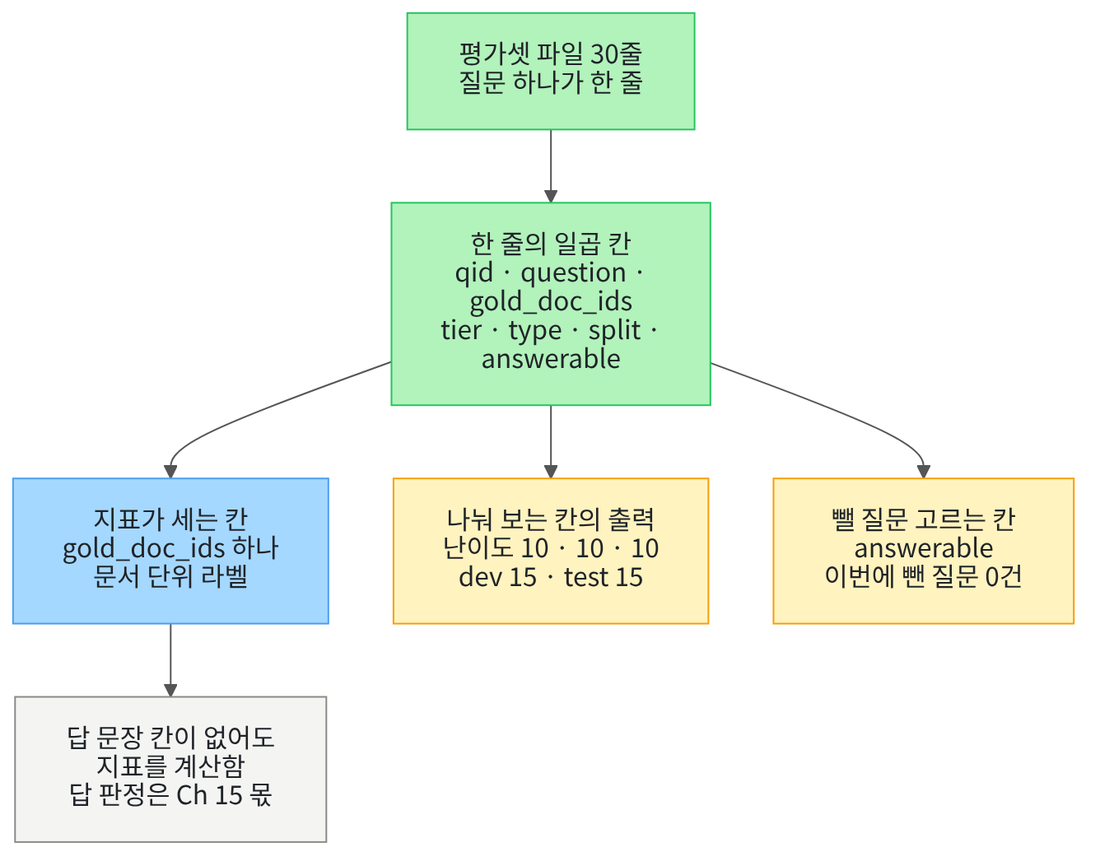

평가셋 한 줄에는 칸이 일곱 개 있습니다. 그 가운데 지표가 세는 칸은 `gold_doc_ids` 하나입니다.
나머지 칸은 결과를 난이도·분할로 나눠 보거나 평가에서 뺄 질문을 고를 때 씁니다.
답 문장을 담는 칸은 없습니다. 이 노트북은 파란 상자 왼쪽 갈래까지 준비하는 자리입니다.

## 1. 준비

이 절은 파일만 읽습니다. 그래서 패키지 설치 셀과 API 키 확인 셀이 없습니다.
첫 셀은 표준 라이브러리 세 개를 불러옵니다.
파일 지문은 `hashlib`으로 만들고, JSONL 한 줄은 `json`으로 딕셔너리로 바꿉니다.

In [1]:
# 평가셋 파일과 실행 기록을 읽고 파일 지문을 만들 이름을 불러옵니다
import hashlib
import json
import os

print("불러온 이름:", "hashlib", "json", "os")

불러온 이름: hashlib json os


**결과 읽기** — 출력 줄은 `불러온 이름: hashlib json os` 하나입니다.
세 이름이 모두 Python에 들어 있어 설치가 필요 없습니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다.
Ch 10 01절과 같은 코드입니다. 후보 경로를 차례로 보고 자료 폴더가 있는 곳에서 멈춥니다.

In [2]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/data/rag-corpus"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.
`notebooks` 폴더에서 열면 셋째 후보, 실습 폴더 맨 위에서 열면 둘째 후보가 나옵니다.

다음 셀은 고른 경로에 파일 이름을 이어 붙여 네 경로를 만듭니다.
그리고 네 파일이 모두 있는지 확인합니다.

In [3]:
# 이 절에서 읽을 파일 네 개의 경로를 만듭니다
dataset_path = root_path + "/labs/part3/ch11-evaluation/data/evaluation-queries.jsonl"
manifest_path = root_path + "/labs/data/rag-corpus/manifest.json"
ch09_log_path = root_path + "/labs/part3/ch09-rag-first-run/runs/continuity-ch09-search.jsonl"
ch10_log_path = root_path + "/labs/part3/ch10-document-processing/runs/continuity-ch10-indexing.jsonl"
print("평가셋 파일이 있는가:", os.path.exists(dataset_path))
print("말뭉치 목록이 있는가:", os.path.exists(manifest_path))
print("Ch 9 기록이 있는가:", os.path.exists(ch09_log_path))
print("Ch 10 기록이 있는가:", os.path.exists(ch10_log_path))

평가셋 파일이 있는가: True
말뭉치 목록이 있는가: True
Ch 9 기록이 있는가: True
Ch 10 기록이 있는가: True


**결과 읽기** — 네 줄 모두 `True`입니다.
앞 두 파일은 이 챕터와 말뭉치의 자료이고, 뒤 두 파일은 앞 챕터가 남긴 실행 기록입니다.
기록 파일이 없으면 실습 묶음을 다시 내려받으세요.

## 2. 평가셋 파일 읽기

평가셋 파일은 JSONL 형식입니다. 한 줄에 질문 하나가 들어 있습니다.
Ch 9 06절에서 실행 기록을 적을 때 쓴 것과 같은 형식입니다.
함수 `json.loads()`는 글 한 줄을 받아 딕셔너리를 반환합니다.

In [4]:
# 평가셋 파일을 한 줄씩 읽어 질문 기록 목록으로 만듭니다
with open(dataset_path, encoding="utf-8") as dataset_file:
    dataset_lines = dataset_file.read().splitlines()

queries = []
for line in dataset_lines:
    queries.append(json.loads(line))
print("평가셋 줄 수:", len(queries))

평가셋 줄 수: 30


**결과 읽기** — 출력 줄은 `평가셋 줄 수: 30`입니다.
질문 30개가 목록 `queries`에 담겼습니다.

## 3. 한 줄의 칸 확인

질문 한 줄에 어떤 칸이 있는지 먼저 봅니다.
메서드 `keys()`는 딕셔너리의 칸 이름을 모아 보여 줍니다.
답 문장을 담는 `answer` 칸이 없는 것도 함께 확인합니다.

In [5]:
# 첫 줄의 칸 이름을 보고 답 문장 칸이 없는지 확인합니다
first_query = queries[0]
print("칸 이름:", first_query.keys())
print("칸 수:", len(first_query))
print("답 문장 칸이 있는가:", "answer" in first_query)

칸 이름: dict_keys(['qid', 'tier', 'question', 'type', 'gold_doc_ids', 'answerable', 'split'])
칸 수: 7
답 문장 칸이 있는가: False


**결과 읽기** — 둘째 줄은 `칸 수: 7`이고 셋째 줄은 `답 문장 칸이 있는가: False`입니다.
첫 줄에 일곱 칸 이름이 모두 나옵니다.
칸 `qid`는 질문 번호, `question`은 질문 글, `gold_doc_ids`는 정답 문서 ID 목록입니다.
칸 `tier`는 난이도, `type`은 질문 갈래, `split`은 개발·시험 분할, `answerable`은 답할 수 있는 질문인지입니다.

다음 셀은 30줄 모두 일곱 칸을 그대로 가졌는지 셉니다.
한 줄이라도 칸이 빠지면 지표를 계산할 때 멈추기 때문입니다.

In [6]:
# 모든 줄이 일곱 칸을 그대로 가졌는지 세어 봅니다
required_names = ["qid", "tier", "question", "type", "gold_doc_ids", "answerable", "split"]
missing_count = 0
for query in queries:
    for name in required_names:
        if name not in query:
            missing_count = missing_count + 1
print("확인한 줄 수:", len(queries))
print("빠진 칸 수:", missing_count)
assert missing_count == 0

확인한 줄 수: 30
빠진 칸 수: 0


**결과 읽기** — 출력 줄은 `확인한 줄 수: 30`과 `빠진 칸 수: 0`입니다.
`assert`도 통과했습니다. 30줄이 모두 같은 칸을 가졌습니다.

## 4. 질문 한 줄 펼쳐 보기

이제 첫 질문 한 줄의 값을 칸마다 출력합니다.
Ch 9 06절과 Ch 10 08절이 쓴 질문 Q001이 이 줄입니다.
정답 문서 ID가 쪽 번호 없는 목록인 것을 눈으로 확인합니다.

In [7]:
# 첫 질문 한 줄의 칸 값을 하나씩 출력합니다
print("질문 번호:", first_query["qid"])
print("난이도:", first_query["tier"])
print("질문 갈래:", first_query["type"])
print("분할:", first_query["split"])
print("답할 수 있는 질문인가:", first_query["answerable"])
print("정답 문서 ID:", first_query["gold_doc_ids"])
print("질문 글:", first_query["question"])

질문 번호: Q001
난이도: easy
질문 갈래: single
분할: dev
답할 수 있는 질문인가: True
정답 문서 ID: ['E01']
질문 글: 미르시립도서관의 정기 휴관일은 언제인가요?


**결과 읽기** — 여섯째 줄은 `정답 문서 ID: ['E01']`입니다.
쪽 번호가 없고 문서 이름만 있습니다.
셋째 줄 `질문 갈래: single`은 근거가 한 문서에 있는 질문이라는 표시입니다.

Ch 9 05절에서는 정답 출처를 쪽까지 적었습니다. 이 챕터의 정답 문서 ID에는 쪽이 없습니다.
마지막 줄의 질문 글은 Ch 9 06절과 Ch 10 08절 기록에 적힌 글과 같아야 합니다. 10절에서 맞춰 봅니다.

## 5. 난이도와 분할 세기

질문이 난이도와 분할에 고르게 퍼져 있는지 셉니다.
빈 딕셔너리를 만들고 `get(키, 기본값)`으로 하나씩 더합니다.
Ch 8 02절에서 쓴 세기 방법과 같습니다.

In [8]:
# 난이도별·분할별 질문 수를 세어 고르게 퍼져 있는지 봅니다
tier_counts = {}
split_counts = {}
for query in queries:
    tier_name = query["tier"]
    split_name = query["split"]
    tier_counts[tier_name] = tier_counts.get(tier_name, 0) + 1
    split_counts[split_name] = split_counts.get(split_name, 0) + 1
print("난이도별 질문 수:", tier_counts)
print("분할별 질문 수:", split_counts)

난이도별 질문 수: {'easy': 10, 'medium': 10, 'hard': 10}
분할별 질문 수: {'dev': 15, 'test': 15}


**결과 읽기** — 첫 줄은 `난이도별 질문 수: {'easy': 10, 'medium': 10, 'hard': 10}`입니다.
쉬움과 보통, 어려움이 10개씩입니다.
둘째 줄은 `분할별 질문 수: {'dev': 15, 'test': 15}`입니다.
개발 분할로 설정을 고르고 시험 분할은 마지막에 한 번만 봅니다.

## 6. 평가에서 뺄 질문 고르기

답할 수 없다고 적힌 질문과 정답 문서 ID가 빈 질문은 평균에서 뺍니다.
그런 질문에 0점을 주면 검색기가 놓친 질문과 섞입니다.
뺀 질문 수는 따로 세어 남겨 둡니다.

In [9]:
# 답할 수 없다고 적혔거나 정답 문서 ID가 빈 줄을 평가에서 뺍니다
excluded_qids = []
included_qids = []
for query in queries:
    if query["answerable"] and len(query["gold_doc_ids"]) > 0:
        included_qids.append(query["qid"])
    else:
        excluded_qids.append(query["qid"])
print("평가 대상 질문 수:", len(included_qids))
print("뺀 질문 수:", len(excluded_qids))
print("뺀 질문 번호:", excluded_qids)

평가 대상 질문 수: 30
뺀 질문 수: 0
뺀 질문 번호: []


**결과 읽기** — 출력 줄은 `평가 대상 질문 수: 30`과 `뺀 질문 수: 0`입니다.
마지막 줄 `뺀 질문 번호: []`는 빈 목록입니다.
이번 평가셋 30줄에는 뺄 질문이 없었습니다. 그래서 이 규칙이 질문을 실제로 빼는 장면은 이번에 실행하지 않았습니다.

## 7. 정답 문서 ID 모으기

정답 문서 ID를 모아 어떤 문서가 몇 번 쓰였는지 셉니다.
칸 `gold_doc_ids`가 목록이라 안쪽 반복문이 하나 더 필요합니다.
정답 문서 ID가 한 개인 질문 수도 함께 셉니다.

In [10]:
# 질문마다 적힌 정답 문서 ID를 모아 문서별 질문 수와 가지 수를 셉니다
gold_counts = {}
single_gold_count = 0
for query in queries:
    if len(query["gold_doc_ids"]) == 1:
        single_gold_count = single_gold_count + 1
    for doc_id in query["gold_doc_ids"]:
        gold_counts[doc_id] = gold_counts.get(doc_id, 0) + 1
print("정답 문서별 질문 수:", gold_counts)
print("정답 문서 가지 수:", len(gold_counts))
print("정답 문서 ID가 한 개인 질문 수:", single_gold_count)

정답 문서별 질문 수: {'E01': 6, 'E02': 4, 'M01': 8, 'M02': 2, 'H01': 8, 'H02': 2}
정답 문서 가지 수: 6
정답 문서 ID가 한 개인 질문 수: 30


**결과 읽기** — 첫 줄에 `{'E01': 6, 'E02': 4, 'M01': 8, 'M02': 2, 'H01': 8, 'H02': 2}`가 나옵니다.
둘째 줄은 `정답 문서 가지 수: 6`입니다. 질문 30개가 문서 여섯 가지에 걸쳐 있습니다.
셋째 줄은 `정답 문서 ID가 한 개인 질문 수: 30`입니다.
정답 문서가 여러 개인 질문은 이번 평가셋에 없습니다.

## 8. 말뭉치 목록과 맞추기

정답 문서 ID가 실제 문서를 가리키는지 말뭉치 목록으로 확인합니다.
목록 파일에는 문서마다 이름과 파일 경로, 쪽 수가 적혀 있습니다.
정답 문서 하나가 쪽 여러 개로 되어 있는 것도 여기서 봅니다.

In [11]:
# 말뭉치 목록과 정답 문서 ID를 맞춰 보고 정답 문서의 쪽 수를 읽습니다
with open(manifest_path, encoding="utf-8") as manifest_file:
    manifest_rows = json.loads(manifest_file.read())

corpus_pages = {}
for item in manifest_rows:
    corpus_pages[item["doc_id"]] = item["pages"]

missing_docs = []
for doc_id in gold_counts:
    if doc_id not in corpus_pages:
        missing_docs.append(doc_id)
print("말뭉치 목록의 문서 수:", len(manifest_rows))
print("목록에 없는 정답 문서 ID:", missing_docs)
print("정답 문서 E01의 쪽 수:", corpus_pages["E01"])

말뭉치 목록의 문서 수: 21
목록에 없는 정답 문서 ID: []
정답 문서 E01의 쪽 수: 5


**결과 읽기** — 첫 줄은 `말뭉치 목록의 문서 수: 21`입니다.
둘째 줄 `목록에 없는 정답 문서 ID: []`는 빈 목록이라 여섯 가지 정답 문서가 모두 목록에 있습니다.
셋째 줄은 `정답 문서 E01의 쪽 수: 5`입니다.
문서 하나가 쪽 다섯 개로 되어 있어도 정답 문서로는 한 건입니다.

## 9. 평가셋 파일 지문 만들기

평가셋을 고치면 옛 기록과 더는 맞지 않습니다.
그래서 앞 챕터 기록에는 평가셋 파일의 지문이 함께 적혀 있습니다.
Ch 7 08절에서 쓴 `hashlib.sha256`으로 같은 지문을 만들어 봅니다.

In [12]:
# 평가셋 파일의 바이트로 지문을 만들어 기록과 맞출 준비를 합니다
with open(dataset_path, "rb") as dataset_bytes_file:
    dataset_bytes = dataset_bytes_file.read()

dataset_fingerprint = hashlib.sha256(dataset_bytes).hexdigest()
print("평가셋 파일 크기(바이트):", len(dataset_bytes))
print("평가셋 파일 지문 앞 10자:", dataset_fingerprint[:10])

평가셋 파일 크기(바이트): 5484
평가셋 파일 지문 앞 10자: 9544b332d5


**결과 읽기** — 출력 줄은 `평가셋 파일 크기(바이트): 5484`와 `평가셋 파일 지문 앞 10자: 9544b332d5`입니다.
지문은 16진수 64자인데 화면에는 앞 10자만 적었습니다.
파일에서 한 글자만 바뀌어도 이 값이 달라집니다.

## 10. 앞 챕터 기록 읽고 라벨 맞추기

Ch 9 06절과 Ch 10 08절은 같은 질문 Q001로 검색해 기록을 남겼습니다.
두 파일을 한 목록으로 읽습니다. 기록마다 어느 챕터에서 왔는지 적힌 칸이 있습니다.

In [13]:
# Ch 9와 Ch 10이 남긴 실행 기록을 한 목록으로 읽습니다
log_paths = [ch09_log_path, ch10_log_path]
records = []
for log_path in log_paths:
    with open(log_path, encoding="utf-8") as log_file:
        log_lines = log_file.read().splitlines()
    for line in log_lines:
        records.append(json.loads(line))
print("읽은 기록 줄 수:", len(records))
print("첫 줄이 온 챕터:", records[0]["source_chapter"])
print("마지막 줄이 온 챕터:", records[-1]["source_chapter"])

읽은 기록 줄 수: 7
첫 줄이 온 챕터: ch09
마지막 줄이 온 챕터: ch10


**결과 읽기** — 첫 줄은 `읽은 기록 줄 수: 7`입니다.
Ch 9 기록 1줄과 Ch 10 기록 6줄을 합한 수입니다.
둘째 줄과 셋째 줄은 `ch09`와 `ch10`으로 나옵니다.

다음 셀은 질문 번호로 평가셋 줄을 찾을 수 있게 딕셔너리를 하나 더 만듭니다.
그리고 기록에 나온 질문 번호를 모아 봅니다.

In [14]:
# 질문 번호로 평가셋 줄을 찾을 수 있게 딕셔너리로 다시 담습니다
query_by_id = {}
for query in queries:
    query_by_id[query["qid"]] = query

record_qids = []
for record in records:
    record_qids.append(record["qid"])
print("평가셋 딕셔너리의 질문 수:", len(query_by_id))
print("기록에 나온 질문 번호:", record_qids)

평가셋 딕셔너리의 질문 수: 30
기록에 나온 질문 번호: ['Q001', 'Q001', 'Q001', 'Q001', 'Q001', 'Q001', 'Q001']


**결과 읽기** — 첫 줄은 `평가셋 딕셔너리의 질문 수: 30`입니다.
둘째 줄의 목록은 `'Q001'`이 일곱 번 이어집니다.
두 챕터가 같은 질문 하나로 실험했기 때문입니다.

다음 셀은 기록의 라벨을 평가셋과 맞춰 봅니다.
맞춰 보는 칸은 질문 글과 정답 문서 ID, 평가셋 파일 지문 셋입니다.

In [15]:
# 기록의 질문 글·정답 문서 ID·평가셋 지문을 평가셋과 하나씩 맞춰 봅니다
mismatch_count = 0
for record in records:
    label = query_by_id[record["qid"]]
    record_fingerprint = record["config"]["inputs"]["evaluation_dataset_sha256"]
    if record["question"] != label["question"]:
        mismatch_count = mismatch_count + 1
    if record["gold_doc_ids"] != label["gold_doc_ids"]:
        mismatch_count = mismatch_count + 1
    if record_fingerprint != dataset_fingerprint:
        mismatch_count = mismatch_count + 1
print("어긋난 칸 수:", mismatch_count)
assert mismatch_count == 0

어긋난 칸 수: 0


**결과 읽기** — 출력 줄은 `어긋난 칸 수: 0`입니다. `assert`도 통과했습니다.
기록 7줄의 질문 글과 정답 문서 ID가 평가셋과 글자까지 같았습니다.
세 기록의 평가셋 지문도 9절에서 만든 값과 같았습니다.
그래서 두 챕터 기록을 같은 라벨로 견줄 수 있습니다.

## 11. 기록의 검색 항목 보기

기록 한 줄에는 검색 결과가 항목 목록으로 들어 있습니다.
항목마다 칸이 다섯 개입니다. Ch 9 06절에서 정한 이름 그대로입니다.
먼저 Ch 9 기록의 항목을 순위 차례로 출력합니다.

In [16]:
# Ch 9 기록 한 줄의 검색 항목을 순위 차례로 출력합니다
ch09_record = records[0]
print("Ch 9 검색 개수 설정:", ch09_record["config"]["retrieval"]["k"])
print("Ch 9 검색 항목 수:", len(ch09_record["retrieved"]))
print("순위 | 문서 ID | 쪽 | 문서 청크 이름")
for hit in ch09_record["retrieved"]:
    print(hit["rank"], "|", hit["doc_id"], "|", hit["page"], "|", hit["chunk_id"])

Ch 9 검색 개수 설정: 2
Ch 9 검색 항목 수: 2
순위 | 문서 ID | 쪽 | 문서 청크 이름
1 | E01 | 1 | ch09:6f9f83db90:0
2 | E01 | 2 | ch09:6f9f83db90:1


**결과 읽기** — 라벨 줄 `순위 | 문서 ID | 쪽 | 문서 청크 이름` 아래에 두 줄이 있습니다.
첫 줄은 `1 | E01 | 1 | ch09:6f9f83db90:0`이고 둘째 줄은 `2 | E01 | 2 | ch09:6f9f83db90:1`입니다.
두 항목의 문서 ID가 모두 `E01`이고 쪽만 1과 2로 다릅니다.
1위 항목의 쪽은 표지 쪽인데도 문서 단위로는 정답 문서입니다.

다음 셀은 Ch 10 기록의 첫 줄을 같은 모양으로 출력합니다.
검색 개수가 5라서 항목이 더 많습니다.

In [17]:
# Ch 10 기록 첫 줄의 검색 항목을 같은 모양으로 출력합니다
ch10_record = records[1]
print("Ch 10 나누기 방식:", ch10_record["config"]["chunk_method"])
print("Ch 10 검색 개수 설정:", ch10_record["config"]["k"])
print("순위 | 문서 ID | 쪽 | 문서 청크 이름")
for hit in ch10_record["retrieved"]:
    print(hit["rank"], "|", hit["doc_id"], "|", hit["page"], "|", hit["chunk_id"])

Ch 10 나누기 방식: char
Ch 10 검색 개수 설정: 5
순위 | 문서 ID | 쪽 | 문서 청크 이름
1 | E01 | 1 | ch10:char:0000
2 | E01 | 2 | ch10:char:0001
3 | M04 | 3 | ch10:char:0181
4 | M04 | 2 | ch10:char:0178
5 | M04 | 3 | ch10:char:0182


**결과 읽기** — 첫 줄은 `Ch 10 나누기 방식: char`이고 둘째 줄은 `Ch 10 검색 개수 설정: 5`입니다.
라벨 줄 아래 다섯 줄의 문서 ID는 `E01` 두 개와 `M04` 세 개입니다.
문서 청크 이름은 `ch10:char:0000` 모양입니다.

앞 셀 출력의 Ch 9 문서 청크 이름과 견주면 번호를 채우는 방식이 다릅니다.
설정 칸 이름도 다릅니다. Ch 9 기록은 검색 개수를 `retrieval` 밑에 적었고 Ch 10 기록은 `config` 바로 밑에 적었습니다.

## 12. 문서 ID 중복 빼고 고유 문서 세기

지표는 문서 단위로 셉니다. 그래서 문서 ID 중복을 먼저 뺍니다.
처음 나온 문서 ID만 순서대로 남기는 함수를 하나 만듭니다.

In [18]:
# 검색 항목에서 문서 ID를 순서대로 모으고 처음 나온 것만 남깁니다
def unique_doc_ids(hit_list):
    doc_ids = []
    for hit in hit_list:
        if hit["doc_id"] not in doc_ids:
            doc_ids.append(hit["doc_id"])
    return doc_ids

**결과 읽기** — 이 셀은 함수만 정의하므로 출력이 없습니다.
반복문 안의 `not in`이 이미 담은 문서 ID를 건너뛰게 합니다.
순서는 검색 순위 그대로 남습니다.

다음 셀에서 두 기록에 같은 함수를 적용합니다.

In [19]:
# 두 기록의 검색 항목 수와 고유 문서 수를 나란히 셉니다
ch09_unique = unique_doc_ids(ch09_record["retrieved"])
ch10_unique = unique_doc_ids(ch10_record["retrieved"])
print("Ch 9 검색 항목 수:", len(ch09_record["retrieved"]), "고유 문서:", ch09_unique)
print("Ch 10 검색 항목 수:", len(ch10_record["retrieved"]), "고유 문서:", ch10_unique)

Ch 9 검색 항목 수: 2 고유 문서: ['E01']
Ch 10 검색 항목 수: 5 고유 문서: ['E01', 'M04']


**결과 읽기** — 첫 줄은 `Ch 9 검색 항목 수: 2 고유 문서: ['E01']`입니다.
둘째 줄은 `Ch 10 검색 항목 수: 5 고유 문서: ['E01', 'M04']`입니다.
Ch 10 기록에서는 항목 다섯 개가 고유 문서 두 개로 줄었습니다.
같은 문서에서 올라온 문서 청크가 여럿이었기 때문입니다.

## 13. 정답 문서가 몇 번째였는지 보기

고유 문서 목록에서 정답 문서가 몇 번째 자리인지 찾습니다.
이 자리가 02절부터 계산할 지표의 바탕입니다.
찾으면 멈추게 `break`를 씁니다.

In [20]:
# 고유 문서 목록에서 정답 문서 ID가 몇 번째 자리인지 찾습니다
def find_gold_rank(doc_ids, gold_doc_ids):
    gold_rank = 0
    for position in range(len(doc_ids)):
        if doc_ids[position] in gold_doc_ids:
            gold_rank = position + 1
            break
    return gold_rank

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.
찾지 못하면 `0`을 반환합니다. 자리 번호는 1부터 세도록 `position`에 1을 더합니다.

다음 셀에서 두 기록의 정답 문서 자리를 출력합니다.

In [21]:
# 두 기록에서 정답 문서가 고유 문서 목록의 몇 번째였는지 출력합니다
gold_doc_ids = first_query["gold_doc_ids"]
ch09_gold_rank = find_gold_rank(ch09_unique, gold_doc_ids)
ch10_gold_rank = find_gold_rank(ch10_unique, gold_doc_ids)
print("정답 문서 ID:", gold_doc_ids)
print("Ch 9 기록에서 정답 문서 순위:", ch09_gold_rank)
print("Ch 10 기록에서 정답 문서 순위:", ch10_gold_rank)
print("Ch 9 1위 항목의 쪽:", ch09_record["retrieved"][0]["page"])

정답 문서 ID: ['E01']
Ch 9 기록에서 정답 문서 순위: 1
Ch 10 기록에서 정답 문서 순위: 1
Ch 9 1위 항목의 쪽: 1


**결과 읽기** — 둘째 줄과 셋째 줄은 `Ch 9 기록에서 정답 문서 순위: 1`과 `Ch 10 기록에서 정답 문서 순위: 1`입니다.
두 기록 모두 정답 문서가 고유 목록의 첫 자리였습니다.
마지막 줄 `Ch 9 1위 항목의 쪽: 1`은 그 항목이 문서의 1쪽에서 왔다는 뜻입니다.
쪽 단위로 보면 답이 있는 쪽이 아니지만 문서 단위로는 정답 문서입니다.

## 14. 값 바꿔 보기 — 개발 분할을 앞에서 자르면

개발 분할 15문항 가운데 앞 5문항만 보고 설정을 고른다고 생각해 보세요.
실행 전에 예상해 봅니다. 앞 5문항은 모두 쉬움 난이도라 정답 문서 갈래가 좁을 것입니다.
정답 문서별 질문 수를 세는 함수를 먼저 정의합니다.

In [22]:
# 질문 목록에서 정답 문서별 질문 수를 세는 함수를 정의합니다
def count_gold_docs(query_list):
    counts = {}
    for query in query_list:
        for doc_id in query["gold_doc_ids"]:
            counts[doc_id] = counts.get(doc_id, 0) + 1
    return counts

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.
7절에서 쓴 세기 방법과 같고, 세는 대상 목록만 인자로 받습니다.

다음 셀에서 개발 분할 질문을 골라 앞 5문항과 15문항 전체를 견줍니다.

In [23]:
# 개발 분할에서 앞 5문항만 볼 때와 15문항을 볼 때의 정답 문서 분포를 견줍니다
dev_queries = []
for query in queries:
    if query["split"] == "dev":
        dev_queries.append(query)

small_counts = count_gold_docs(dev_queries[:5])
full_counts = count_gold_docs(dev_queries)
print("개발 분할 질문 수:", len(dev_queries))
print("앞 5문항의 정답 문서 분포:", small_counts)
print("앞 5문항의 정답 문서 가지 수:", len(small_counts))
print("15문항 전체의 정답 문서 분포:", full_counts)
print("15문항 전체의 정답 문서 가지 수:", len(full_counts))

개발 분할 질문 수: 15
앞 5문항의 정답 문서 분포: {'E01': 5}
앞 5문항의 정답 문서 가지 수: 1
15문항 전체의 정답 문서 분포: {'E01': 5, 'M01': 5, 'H01': 5}
15문항 전체의 정답 문서 가지 수: 3


**결과 읽기** — 둘째 줄은 `앞 5문항의 정답 문서 분포: {'E01': 5}`이고 가지 수는 `1`입니다.
예상대로 문서 한 가지에 몰렸습니다.
넷째 줄은 `15문항 전체의 정답 문서 분포: {'E01': 5, 'M01': 5, 'H01': 5}`이고 가지 수는 `3`입니다.

7절에서 본 평가셋 30문항 전체의 가지 수는 여섯이었습니다.
볼 질문을 줄일수록 정답 문서 갈래가 좁아집니다.

## 15. 정리

1. 평가셋 파일은 30줄이고 한 줄에 칸이 일곱 개이며 답 문장 칸은 없습니다.
2. 난이도는 10개씩, 개발 분할과 시험 분할은 15개씩이고 이번에 뺄 질문은 0건이었습니다.
3. 앞 챕터 기록 7줄의 라벨은 평가셋과 어긋난 칸이 0개였고, 검색 항목 5개는 고유 문서 2개로 줄었습니다.

다음 02절에서는 고유 문서 목록의 앞 50개에 정답 문서가 들어왔는지 Recall@50으로 잽니다.